
## Observations

- The original dataset contained 2,748 labelled reviews.
- No missing values were found.
- After removing 17 duplicate rows, 2,731 reviews remained.
- TF-IDF was used to convert text into numerical features.
- Logistic Regression achieved an accuracy of 80.80%.
- The model correctly classified 442 out of 547 test reviews.
- All four manually entered example reviews were classified correctly.

## Conclusion

In this practical, a sentiment analysis model was developed using traditional machine learning techniques. The dataset was cleaned, preprocessed, and transformed using TF-IDF. Logistic Regression was used to classify reviews as positive or negative.

The model achieved 80.80% accuracy, demonstrating that traditional machine learning can be effective for sentiment classification. However, some reviews were misclassified, indicating opportunities for improvement.

## Learning Outcomes

- Learned how to load and explore text datasets.
- Applied text preprocessing techniques.
- Understood TF-IDF feature extraction.
- Trained a Logistic Regression classifier.
- Evaluated the model using accuracy, precision, recall, F1-score, and a confusion matrix.
- Tested the trained model on new review sentences.


In [15]:

# New reviews for testing
new_reviews = [
    "This product is absolutely amazing!",
    "I am very disappointed with this product.",
    "The quality is excellent and I love it.",
    "This was a terrible experience."
]

# Preprocess the reviews
cleaned_reviews = [clean_text(review) for review in new_reviews]

# Convert reviews into TF-IDF features
review_features = tfidf.transform(cleaned_reviews)

# Predict sentiments
predictions = model.predict(review_features)

# Display predictions
for review, prediction in zip(new_reviews, predictions):
    sentiment = "Positive" if prediction == 1 else "Negative"
    print("Review:", review)
    print("Predicted Sentiment:", sentiment)
    print()


Review: This product is absolutely amazing!
Predicted Sentiment: Positive

Review: I am very disappointed with this product.
Predicted Sentiment: Negative

Review: The quality is excellent and I love it.
Predicted Sentiment: Positive

Review: This was a terrible experience.
Predicted Sentiment: Negative



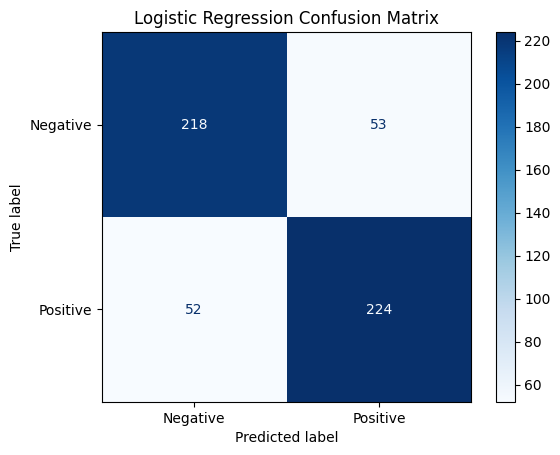

In [14]:

from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Negative", "Positive"],
    cmap="Blues"
)

plt.title("Logistic Regression Confusion Matrix")
plt.show()


In [13]:

# Display model accuracy
print("Model Accuracy:", accuracy_score(y_test, y_pred))

# Display classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Display confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Model Accuracy: 0.8080438756855576

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.80      0.81       271
           1       0.81      0.81      0.81       276

    accuracy                           0.81       547
   macro avg       0.81      0.81      0.81       547
weighted avg       0.81      0.81      0.81       547


Confusion Matrix:
[[218  53]
 [ 52 224]]


In [12]:

# Create the Logistic Regression model
model = LogisticRegression(max_iter=1000, random_state=42)

# Train the model
model.fit(X_train_tfidf, y_train)

# Predict sentiments for the test data
y_pred = model.predict(X_test_tfidf)

print("Model trained successfully!")
print("Accuracy:", accuracy_score(y_test, y_pred))


Model trained successfully!
Accuracy: 0.8080438756855576


In [11]:

# Separate features and labels
X = data["cleaned_sentence"]
y = data["sentiment"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Convert text into numerical features using TF-IDF
tfidf = TfidfVectorizer(max_features=5000)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training samples:", X_train_tfidf.shape[0])
print("Testing samples:", X_test_tfidf.shape[0])
print("Number of TF-IDF features:", X_train_tfidf.shape[1])


Training samples: 2184
Testing samples: 547
Number of TF-IDF features: 4508


In [10]:

import re

# Function to clean review text
def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

# Apply text cleaning
data["cleaned_sentence"] = data["sentence"].apply(clean_text)

# Display original and cleaned reviews
display(data[["sentence", "cleaned_sentence"]].head())


,sentence,cleaned_sentence
0,So there is no way for me to plug it in here i...,so there is no way for me to plug it in here i...
1,"Good case, Excellent value.",good case excellent value
2,Great for the jawbone.,great for the jawbone
3,Tied to charger for conversations lasting more...,tied to charger for conversations lasting more...
4,The mic is great.,the mic is great


In [9]:

# Remove duplicate rows
data = data.drop_duplicates().reset_index(drop=True)

# Verify cleaning
print("Dataset Shape After Cleaning:", data.shape)
print("Duplicate Rows Remaining:", data.duplicated().sum())
print("Missing Values Remaining:")
print(data.isnull().sum())


Dataset Shape After Cleaning: (2731, 2)
Duplicate Rows Remaining: 0
Missing Values Remaining:
sentence     0
sentiment    0
dtype: int64


In [8]:

print("Dataset Shape:", data.shape)

print("\nMissing Values:")
print(data.isnull().sum())

print("\nDuplicate Rows:", data.duplicated().sum())

print("\nSentiment Distribution:")
print(data["sentiment"].value_counts())


Dataset Shape: (2748, 2)

Missing Values:
sentence     0
sentiment    0
dtype: int64

Duplicate Rows: 17

Sentiment Distribution:
sentiment
1    1386
0    1362
Name: count, dtype: int64


In [7]:

import pandas as pd

# Dataset filenames
files = [
    "amazon_cells_labelled.txt",
    "imdb_labelled.txt",
    "yelp_labelled.txt"
]

dataframes = []

# Load each dataset
for file in files:
    df = pd.read_csv(
        "/" + file,
        sep="\t",
        header=None,
        names=["sentence", "sentiment"]
    )
    dataframes.append(df)

# Combine all three datasets
data = pd.concat(dataframes, ignore_index=True)

print("Dataset loaded successfully!")
print("Total sentences:", len(data))

display(data.head())


Dataset loaded successfully!
Total sentences: 2748


,sentence,sentiment
0,So there is no way for me to plug it in here i...,0
1,"Good case, Excellent value.",1
2,Great for the jawbone.,1
3,Tied to charger for conversations lasting more...,0
4,The mic is great.,1


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("All libraries imported successfully!")


All libraries imported successfully!


# Lab 01: Sentiment Analysis Using Traditional Machine Learning

## Objective
To develop a machine learning model that classifies text into positive and negative sentiments.